In [1]:
print("Let's Start")

Let's Start


tranverse on link to work on this - https://www.kaggle.com/code/chirag2775/4-catvsdog/edit

In [2]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("anthonytherrien/dog-vs-cat")

print("Path to dataset files:", path)

Path to dataset files: /kaggle/input/d/anthonytherrien/dog-vs-cat


In [9]:
import tensorflow
from tensorflow import keras
from keras import Sequential
from keras.layers import Dense , Conv2D , Flatten , MaxPooling2D , Dropout , BatchNormalization

In [2]:
test_data = keras.utils.image_dataset_from_directory(
    directory = "/kaggle/input/dogsvscats/test",
    labels="inferred",
    label_mode = "int",
    batch_size = 32,
    image_size = (128,128)
    
)



Found 5000 files belonging to 2 classes.


I0000 00:00:1767102767.844205      55 gpu_device.cc:2019] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 15513 MB memory:  -> device: 0, name: Tesla P100-PCIE-16GB, pci bus id: 0000:00:04.0, compute capability: 6.0


In [3]:
train_data = keras.utils.image_dataset_from_directory(
    directory = "/kaggle/input/dogsvscats/train",
    labels="inferred",
    label_mode = "int",
    batch_size = 32,
    image_size = (128,128)
    
)


Found 20000 files belonging to 2 classes.


In [4]:
def process(image , label):
    image = tensorflow.cast(image/255 , tensorflow.float32)
    return image ,label

train_data= train_data.map(process)
test_data = test_data.map(process)

In [11]:
model = Sequential()

model.add(Conv2D(32 , kernel_size=(3,3) , padding='valid' , activation='relu' , input_shape=(128 ,128,3)))
model.add(BatchNormalization())
model.add(MaxPooling2D(pool_size=(2,2) , strides=2 , padding='valid'))

model.add(Conv2D(64 , kernel_size=(3,3) , padding='valid' , activation='relu'))
model.add(BatchNormalization())
model.add(MaxPooling2D(pool_size=(2,2) , strides=2 , padding='valid'))

model.add(Conv2D(128 , kernel_size=(3,3) , padding='valid' , activation='relu'))
model.add(BatchNormalization())
model.add(MaxPooling2D(pool_size=(2,2) , strides=2 , padding='valid'))

model.add(Flatten())

model.add(Dense(128 , activation='relu' ,  input_shape=(115200,)))
model.add(Dropout(0.1))
model.add(Dense(64 , activation='relu'))
model.add(Dropout(0.1))
model.add(Dense(1 , activation='sigmoid'))
model.summary()

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_6 (Conv2D)               │ (None, 126, 126, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 126, 126, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_6 (MaxPooling2D)  │ (None, 63, 63, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_7 (Conv2D)               │ (None, 61, 61, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_4           │ (None, 61, 61, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_7 (MaxPooling2D)  │ (None, 30, 30, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_8 (Conv2D)               │ (None, 28, 28, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_5           │ (None, 28, 28, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_8 (MaxPooling2D)  │ (None, 14, 14, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_2 (Flatten)             │ (None, 25088)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 128)            │     3,211,392 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,313,857 (12.64 MB)

 Trainable params: 3,313,409 (12.64 MB)

 Non-trainable params: 448 (1.75 KB)

In [12]:
model.compile(loss='binary_crossentropy' , optimizer='adam' , metrics=['accuracy'])
history = model.fit(train_data , epochs=10 , validation_data=test_data)


Epoch 1/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 23s 28ms/step - accuracy: 0.5945 - loss: 1.1612 - val_accuracy: 0.6238 - val_loss: 0.6505
Epoch 2/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 17s 27ms/step - accuracy: 0.7360 - loss: 0.5383 - val_accuracy: 0.7198 - val_loss: 0.5410
Epoch 3/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 18s 28ms/step - accuracy: 0.7849 - loss: 0.4480 - val_accuracy: 0.7664 - val_loss: 0.5086
Epoch 4/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 17s 27ms/step - accuracy: 0.8274 - loss: 0.3800 - val_accuracy: 0.7602 - val_loss: 0.4714
Epoch 5/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 17s 26ms/step - accuracy: 0.8639 - loss: 0.3065 - val_accuracy: 0.8022 - val_loss: 0.6059
Epoch 6/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 16s 26ms/step - accuracy: 0.8897 - loss: 0.2548 - val_accuracy: 0.7922 - val_loss: 0.5816
Epoch 7/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 16s 26ms/step - accuracy: 0.9189 - loss: 0.1893 - val_accuracy: 0.8120 - val_loss: 0.5131
Epoch 8/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 17s 27ms/step - accuracy: 0.9329 - loss: 0.1587 - 

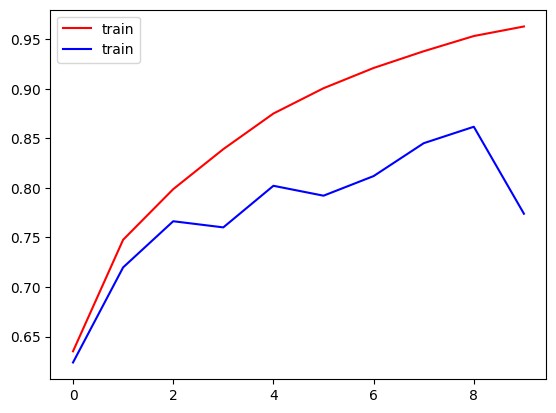

In [13]:
import matplotlib.pyplot as plt
plt.plot(history.history['accuracy'] , color='red' , label='train')
plt.plot(history.history['val_accuracy'] , color='blue' , label = 'train')
plt.legend()
plt.show()

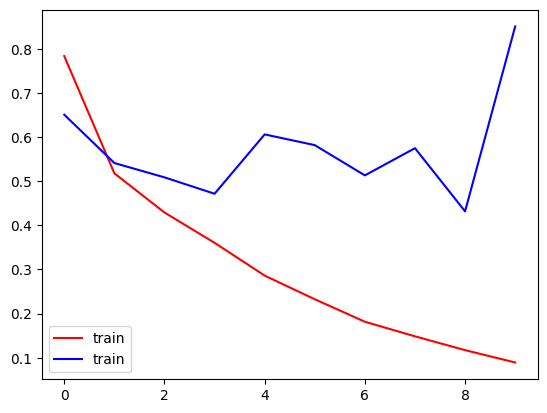

In [14]:
plt.plot(history.history['loss'] , color='red' , label='train')
plt.plot(history.history['val_loss'] , color='blue' , label = 'train')
plt.legend()
plt.show()